A processar RQ1...


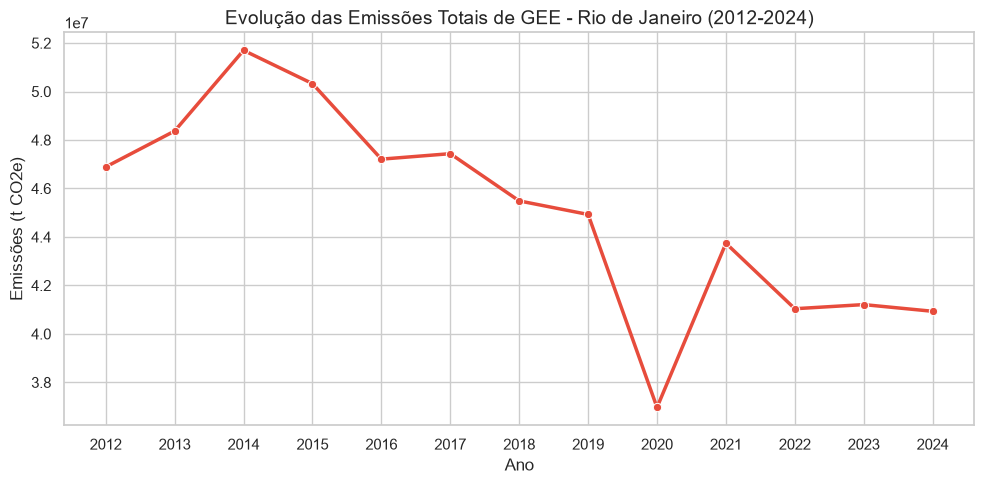

A processar RQ2...


C:\Users\c4x\AppData\Local\Temp\ipykernel_23920\3635836692.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_setores_escopo1, y='setor', x='emissao_tCO2e', palette='viridis')


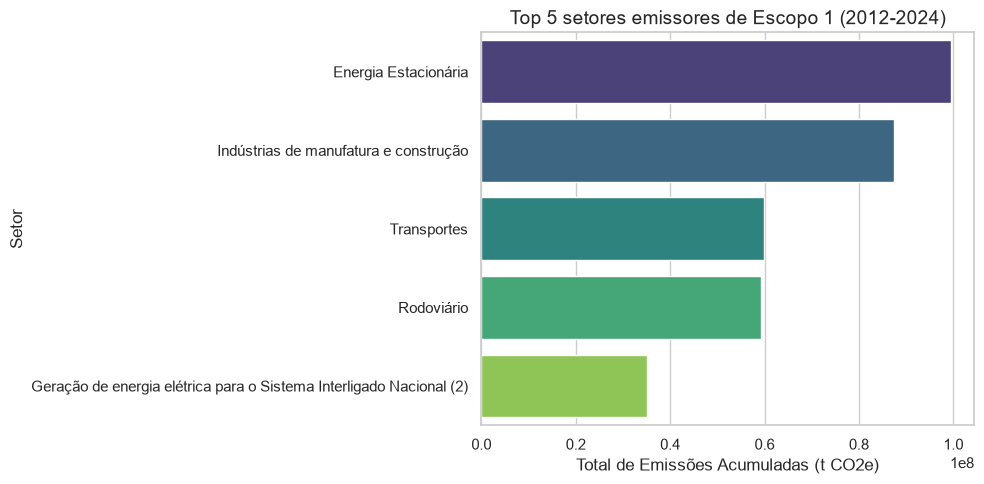

A processar RQ3...


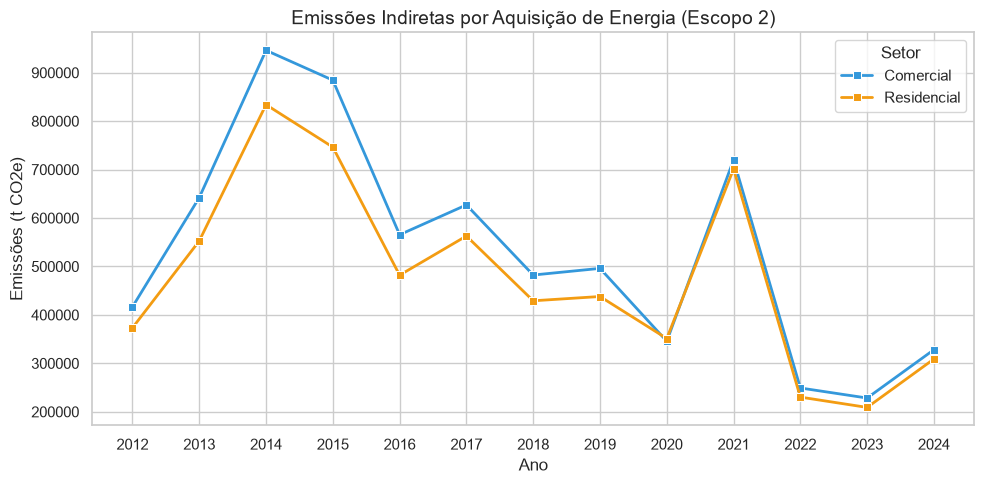


[+] Gráficos gerados com sucesso e guardados na pasta docs/assets/!


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Configuração de estilo dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# 1. Carregar os dados limpos
df = pd.read_csv('../data/processed/emissoes_gee_rj_limpo.csv')

# Garantir que a pasta de assets existe para guardar os gráficos
os.makedirs('../docs/assets', exist_ok=True)

# ==========================================
# RQ1: Evolução Temporal das Emissões Totais
# ==========================================
print("A processar RQ1...")
df_total_ano = df[df['escopo'] == 'Total'].groupby('ano')['emissao_tCO2e'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=df_total_ano, x='ano', y='emissao_tCO2e', marker='o', linewidth=2.5, color='#e74c3c')
plt.title('Evolução das Emissões Totais de GEE - Rio de Janeiro (2012-2024)', fontsize=14)
plt.ylabel('Emissões (t CO2e)', fontsize=12)
plt.xlabel('Ano', fontsize=12)
plt.xticks(df_total_ano['ano'])
plt.tight_layout()
plt.savefig('../docs/assets/rq1_evolucao_temporal.png', dpi=300)
plt.show()

# ==========================================
# RQ2: Principais Ofensores de Emissões Diretas (Escopo 1)
# ==========================================
print("A processar RQ2...")
# Filtrar apenas Escopo 1 e remover agregações genéricas
df_escopo1 = df[(df['escopo'] == 'Escopo 1') & (df['emissao_tCO2e'] > 0)]
# Somar por setor e pegar os 5 maiores
top_setores_escopo1 = df_escopo1.groupby('setor')['emissao_tCO2e'].sum().nlargest(5).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=top_setores_escopo1, y='setor', x='emissao_tCO2e', palette='viridis')
plt.title('Top 5 setores emissores de Escopo 1 (2012-2024)', fontsize=14)
plt.xlabel('Total de Emissões Acumuladas (t CO2e)', fontsize=12)
plt.ylabel('Setor', fontsize=12)
plt.tight_layout()
plt.savefig('../docs/assets/rq2_ofensores_escopo1.png', dpi=300)
plt.show()

# ==========================================
# RQ3: Matriz Energética - Residencial vs Comercial (Escopo 2)
# ==========================================
print("A processar RQ3...")
# Filtrar Escopo 2 e focar em Residencial e Comercial
df_escopo2 = df[(df['escopo'] == 'Escopo 2') & (df['setor'].isin(['Residencial', 'Comercial']))]

plt.figure(figsize=(10, 5))
sns.lineplot(data=df_escopo2, x='ano', y='emissao_tCO2e', hue='setor', marker='s', linewidth=2, palette=['#3498db', '#f39c12'])
plt.title('Emissões Indiretas por Aquisição de Energia (Escopo 2)', fontsize=14)
plt.ylabel('Emissões (t CO2e)', fontsize=12)
plt.xlabel('Ano', fontsize=12)
plt.xticks(df_total_ano['ano'])
plt.legend(title='Setor')
plt.tight_layout()
plt.savefig('../docs/assets/rq3_matriz_energetica.png', dpi=300)
plt.show()

print("\n[+] Gráficos gerados com sucesso e guardados na pasta docs/assets/!")